In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('placement.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Text(0, 0.5, 'Package(in lpa)')

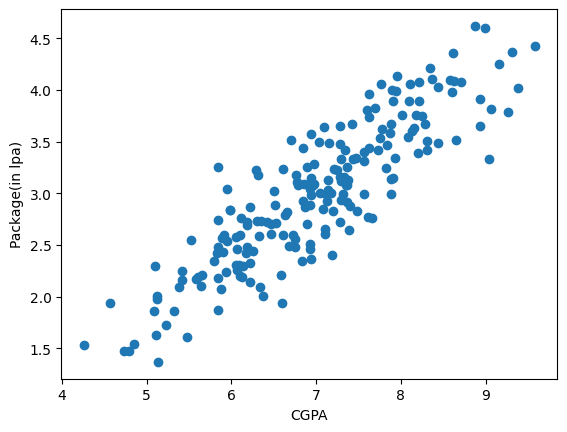

In [19]:
plt.scatter(df['cgpa'],df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [5]:
X=df.iloc[:,0:1]
y=df.iloc[:,-1]

In [6]:
X

,cgpa
0,6.89
1,5.12
2,7.82
3,7.42
4,6.94
...,...
195,6.93
196,5.89
197,7.21
198,7.63


In [7]:
y

,package
0,3.26
1,1.98
2,3.25
3,3.67
4,3.57
...,...
195,2.46
196,2.57
197,3.24
198,3.96


In [8]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [10]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [18]:
lr.predict(X_test.iloc[[0]])

array([3.89111601])

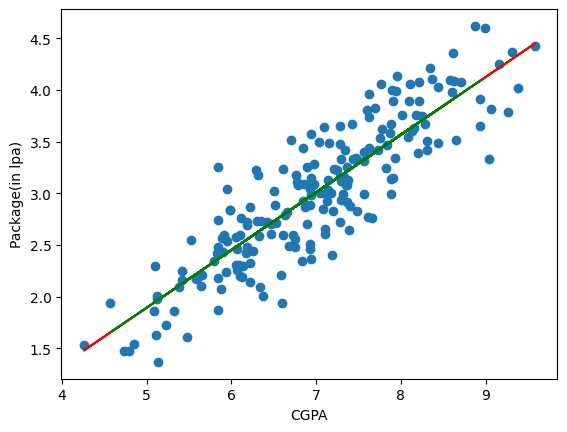

In [21]:
plt.scatter(df['cgpa'],df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')
plt.plot(X_train,lr.predict(X_train),color='red') #best-fit line for trained data
plt.plot(X_test,lr.predict(X_test),color='green')


In [22]:
#y=mx+b
m = lr.coef_
m

array([0.55795197])

In [23]:
b=lr.intercept_
b

np.float64(-0.8961119222429144)

In [24]:
X_test.iloc[[0]] * m + b

,cgpa
112,3.891116


REG metrics

In [25]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [26]:
print('MAE:',mean_absolute_error(y_test,lr.predict(X_test)))
print('MSE:',mean_squared_error(y_test,lr.predict(X_test)))
print('RMSE:',np.sqrt(mean_squared_error(y_test,lr.predict(X_test))))
print('R2 score:',r2_score(y_test,lr.predict(X_test)))
r2=r2_score(y_test,lr.predict(X_test))
print('Adjusted R2:' ,1-(1-r2)*(X_test.shape[0]-1)/(X_test.shape[0]-X_test.shape[1]-1))

MAE: 0.2884710931878175
MSE: 0.12129235313495527
RMSE: 0.34827051717731616
R2 score: 0.780730147510384
Adjusted R2: 0.7749598882343415
